# Machine Learning for Sound and Music 2026
## Lab 1: Music Genre Classification
##### Author: Lidia Wiśniewska
-----
### Background
Automatic genre classification using machine learning techniques is pivotal in managing
and enriching large-scale text and music collections. In textual data, assigning genre
labels—such as promotional or legal—enhances information retrieval by enabling users
to filter documents based on their specific needs, thereby improving search relevance and
efficiency. This automated labeling also aids in the curation of web corpora, ensuring a
diverse and representative dataset for training language models, which is essential for
advancing natural language processing applications. 

In the realm of music, genre classification facilitates the organization of extensive audio libraries, supporting
personalized recommendation systems and efficient content-based music retrieval. By
analyzing audio features, machine learning models can accurately categorize tracks into
genres like classical, jazz, or hip-hop, enhancing user experience in music streaming
services. Overall, the integration of automatic genre classification streamlines the
management of vast information repositories, making them more accessible and user-
centric

---
### Approach
This notebook implements genre classification using tradiitonal ML techniques:
* Logistic Regression
* kNN
* Decision Trees
* Random Forest
* ANN

---
### Structure
The notebook structure looks as follows: <br>
    1. [Data loading](#1-data-loading-and-eda)<br>
    2. [Feature engineering](#2-feature-engineering)<br>
    3. [Classification](#3-classification)<br>
    4. [Evaluation](#4-evaluation)<br>
    5. [Research questions]()<br>

    



## 1. Data loading and EDA

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 250)


In [19]:
f30_df = pd.read_csv("./data/features_30_sec.csv", sep=",")
f30_df.columns = f30_df.columns.str.strip() #erase the whitespaces
feature_colnames_30 = f30_df.columns.drop('label').tolist()

print(f"Shape: {f30_df.shape[0]} rows, {f30_df.shape[1]} columns\n")
f30_df.head(10)

Shape: 1000 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,1.297741e+05,2002.449060,85882.761315,3805.839606,9.015054e+05,0.083045,0.000767,-4.529724e-05,0.008172,0.000008,0.005698,123.046875,-113.570648,2564.207520,121.571793,295.913818,-19.168142,235.574432,42.366421,151.106873,-6.364664,167.934799,18.623499,89.180840,-13.704891,67.660492,15.343150,68.932579,-12.274110,82.204201,10.976572,63.386311,-8.326573,61.773094,8.803792,51.244125,-3.672300,41.217415,5.747995,40.554478,-5.162882,49.775421,0.752740,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,3.758501e+05,2039.036516,213843.755497,3550.522098,2.977893e+06,0.056040,0.001448,1.395807e-04,0.005099,-0.000178,0.003063,67.999589,-207.501694,7764.555176,123.991264,560.259949,8.955127,572.810913,35.877647,264.506104,2.907320,279.932922,21.510466,156.477097,-8.560436,200.849182,23.370686,142.555954,-10.099661,166.108521,11.900497,104.358612,-5.555639,105.173630,5.376327,96.197212,-2.231760,64.914291,4.220140,73.152534,-6.012148,52.422142,0.927998,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,1.564676e+05,1747.702312,76254.192257,3042.260232,7.840345e+05,0.076291,0.001007,2.105576e-06,0.016342,-0.000019,0.007458,161.499023,-90.722595,3319.044922,140.446304,508.765045,-29.093889,411.781219,31.684334,144.090317,-13.984504,155.493759,25.764742,74.548401,-13.664875,106.981827,11.639934,106.574875,-11.783643,65.447945,9.718760,67.908859,-13.133803,57.781425,5.791199,64.480209,-8.907628,60.385151,-1.077000,57.711136,-9.229274,36.580986,2.451690,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,1.843559e+05,1596.412872,166441.494769,2184.745799,1.493194e+06,0.033309,0.000423,4.583644e-07,0.019054,-0.000014,0.002712,63.024009,-199.544205,5507.517090,150.090897,456.505402,5.662678,257.161163,26.859079,158.267303,1.771399,268.034393,14.234031,126.794128,-4.832006,155.912079,9.286494,81.273743,-0.759186,92.114090,8.137607,71.314079,-3.200653,110.236687,6.079319,48.251999,-2.480174,56.799400,-1.079305,62.289902,-2.870789,51.651592,0.780874,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,3.433999e+05,1748.172116,88445.209036,3579.757627,1.572978e+06,0.101461,0.001954,-1.756129e-05,0.004814,-0.000010,0.003094,135.999178,-160.337708,5195.291992,126.219635,853.784729,-35.587811,333.792938,22.148071,193.456100,-32.478600,336.276825,10.852294,134.831573,-23.352329,93.257095,0.498434,124.672127,-11.793437,130.073349,1.207256,99.675575,-13.088418,80.254066,-2.813867,86.430626,-6.933385,89.555443,-7.552725,70.943336,-9.164666,75.793404,-4.520576,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
5,blues.00005.wav,661794,0.302456,0.087532,0.103494,0.003981,1831.993940,1.030482e+06,1729.653287,201910.508633,3481.517592,3.274440e+06,0.094042,0.0062

In [ ]:
f3_df = pd.read_csv("./data/features_3_sec.csv", sep=",")
f3_df.columns = f3_df.columns.str.strip() #erase the whitespaces
feature_colnames_3 = f3_df.columns.drop('label').tolist()

print(f"Shape: {f3_df.shape[0]} rows, {f3_df.shape[1]} columns\n")
f3_df.head(10)

Shape: 9990 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues
5,blues.00000.5.wav,66149,0.376670,0.089702,0.132618,0.003583,1994.915219,211700.619569,2152.767854,74263.873102,...,31.448069,-3.448373,34.284130,-0.416165,40.791092,-3.649625,32.457901,3.025218,28.892687,blues
6,blues.00000.6.wav,66149,0.379909,0.088827,0.130335,0.003166,1962.150096,177443.070045,2146.503479,98020.541422,...,33.954071,-2.068194,25.623655,1.428141,47.957699,-3.267124,39.382240,3.276939,25.999132,blues
7,blues.00000.7.wav,66149,0.331880,0.092119,0.140600,0.002546,1701.890924,35678.130616,1979.387612,36670.725886,...,38.456211,-3.637886,24.530296,-0.105148,26.716150,-2.016985,23.150423,0.210787,42.512966,blues
8,blues.00000.8.wav,66149,0.347877,0.094209,0.133130,0.002538,1746.473502,138073.931244,1887.619723,117069.920049,...,44.311455,-4.370029,29.873167,2.114592,33.843155,-2.264663,80.812393,3.758598,97.618835,blues
9,blues.00000.9.wav,66149,0.358061,0.082957,0.115312,0.001846,1763.948942,61493.423121,1874.195710,51944.921435,...,43.967834,-3.448304,48.671944,0.099792,41.839546,-7.677177,96.253654,0.791776,40.416420,blues


We observe that the columns are the same for both of the datasets, where `f3_df` has more rows as they are the cut files from `f30_df`.

In [5]:
#f30_df
missing_counts = f30_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [6]:
#f3_df
missing_counts = f3_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [7]:
#check the duplicates only of feature columns to inspect possible mislabeling
duplicate_rows = f30_df[f30_df.duplicated(subset=feature_colnames_30, keep=False)] #keeping all versions to inspect

print(f"\nDuplicate rows found: {len(duplicate_rows)}")
duplicate_rows.sort_values(by=feature_colnames_30[:5])


Duplicate rows found: 0


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label


In [8]:
#check the duplicates only of feature columns to inspect possible mislabeling
duplicate_rows = f3_df[f3_df.duplicated(subset=feature_colnames_3, keep=False)] #keeping all versions to inspect

print(f"\nDuplicate rows found: {len(duplicate_rows)}")
duplicate_rows.sort_values(by=feature_colnames_3[:5])


Duplicate rows found: 0


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label


We observe no duplicates, no mislabellings and no missing values.

#### Datatypes

In [10]:
print(f"Unique data types: {f30_df.dtypes.unique().tolist()}")
print("\nAll column data types:\n")
f30_df.dtypes

Unique data types: [<StringDtype(storage='python', na_value=nan)>, dtype('int64'), dtype('float64')]

All column data types:



filename                       str
length                       int64
chroma_stft_mean           float64
chroma_stft_var            float64
rms_mean                   float64
rms_var                    float64
spectral_centroid_mean     float64
spectral_centroid_var      float64
spectral_bandwidth_mean    float64
spectral_bandwidth_var     float64
rolloff_mean               float64
rolloff_var                float64
zero_crossing_rate_mean    float64
zero_crossing_rate_var     float64
harmony_mean               float64
harmony_var                float64
perceptr_mean              float64
perceptr_var               float64
tempo                      float64
mfcc1_mean                 float64
mfcc1_var                  float64
mfcc2_mean                 float64
mfcc2_var                  float64
mfcc3_mean                 float64
mfcc3_var                  float64
mfcc4_mean                 float64
mfcc4_var                  float64
mfcc5_mean                 float64
mfcc5_var           

The dataset contains only numeric data (float) with filename in str, which will not be useful for classification anyway - just for the grouping aspect in train/test split for f3_df. Additionally, we have one value in integer (length), which will not be useful for classification either.

In [13]:
cat_columns = f30_df.select_dtypes(include='string').columns
num_columns = f30_df.select_dtypes(include="number").columns

assert len(num_columns)+len(cat_columns)==f30_df.shape[1], "You just lost some columns..."

#### F30_df columns

In [14]:
feature_df_descr_30 = f30_df[num_columns].describe()
feature_df_descr_30

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,662030.846000,0.378682,0.086340,0.130930,0.003051,2201.780898,4.696916e+05,2242.541070,137079.155165,4571.549304,...,1.148144,60.730958,-3.966028,62.633624,0.507696,63.712586,-2.328761,66.231930,-1.095348,70.126096
std,1784.073992,0.081705,0.007735,0.065683,0.003634,715.960600,4.008995e+05,526.316473,96455.666326,1574.791602,...,4.578948,33.781951,4.549697,33.479172,3.869105,34.401977,3.755957,37.174631,3.837007,45.228512
min,660000.000000,0.171939,0.044555,0.005276,0.000004,570.040355,7.911251e+03,898.066208,10787.185064,749.140636,...,-15.693844,9.169314,-17.234728,13.931521,-11.963694,15.420555,-18.501955,13.487622,-19.929634,7.956583
25%,661504.000000,0.319562,0.082298,0.086657,0.000942,1627.697311,1.843505e+05,1907.240605,67376.554428,3380.069642,...,-1.863280,40.376442,-7.207225,40.830875,-2.007015,41.884240,-4.662925,41.710184,-3.368996,42.372865
50%,661794.000000,0.383148,0.086615,0.122443,0.001816,2209.263090,3.384862e+05,2221.392843,111977.548036,4658.524473,...,1.212809,52.325077,-4.065605,54.717674,0.669643,54.804890,-2.393862,57.423059,-1.166289,59.186117
75%,661794.000000,0.435942,0.091256,0.175682,0.003577,2691.294667,6.121479e+05,2578.469836,182371.576801,5533.810460,...,4.359662,71.691755,-0.838737,75.040838,3.119212,75.385832,0.150573,78.626444,1.312615,85.375374
max,675808.000000,0.663685,0.108111,0.397973,0.027679,4435.243901,3.036843e+06,3509.646417,694784.811549,8677.672688,...,13.457150,392.932373,11.482946,406.058868,15.388390,332.905426,14.694924,393.161987,15.369627,506.065155


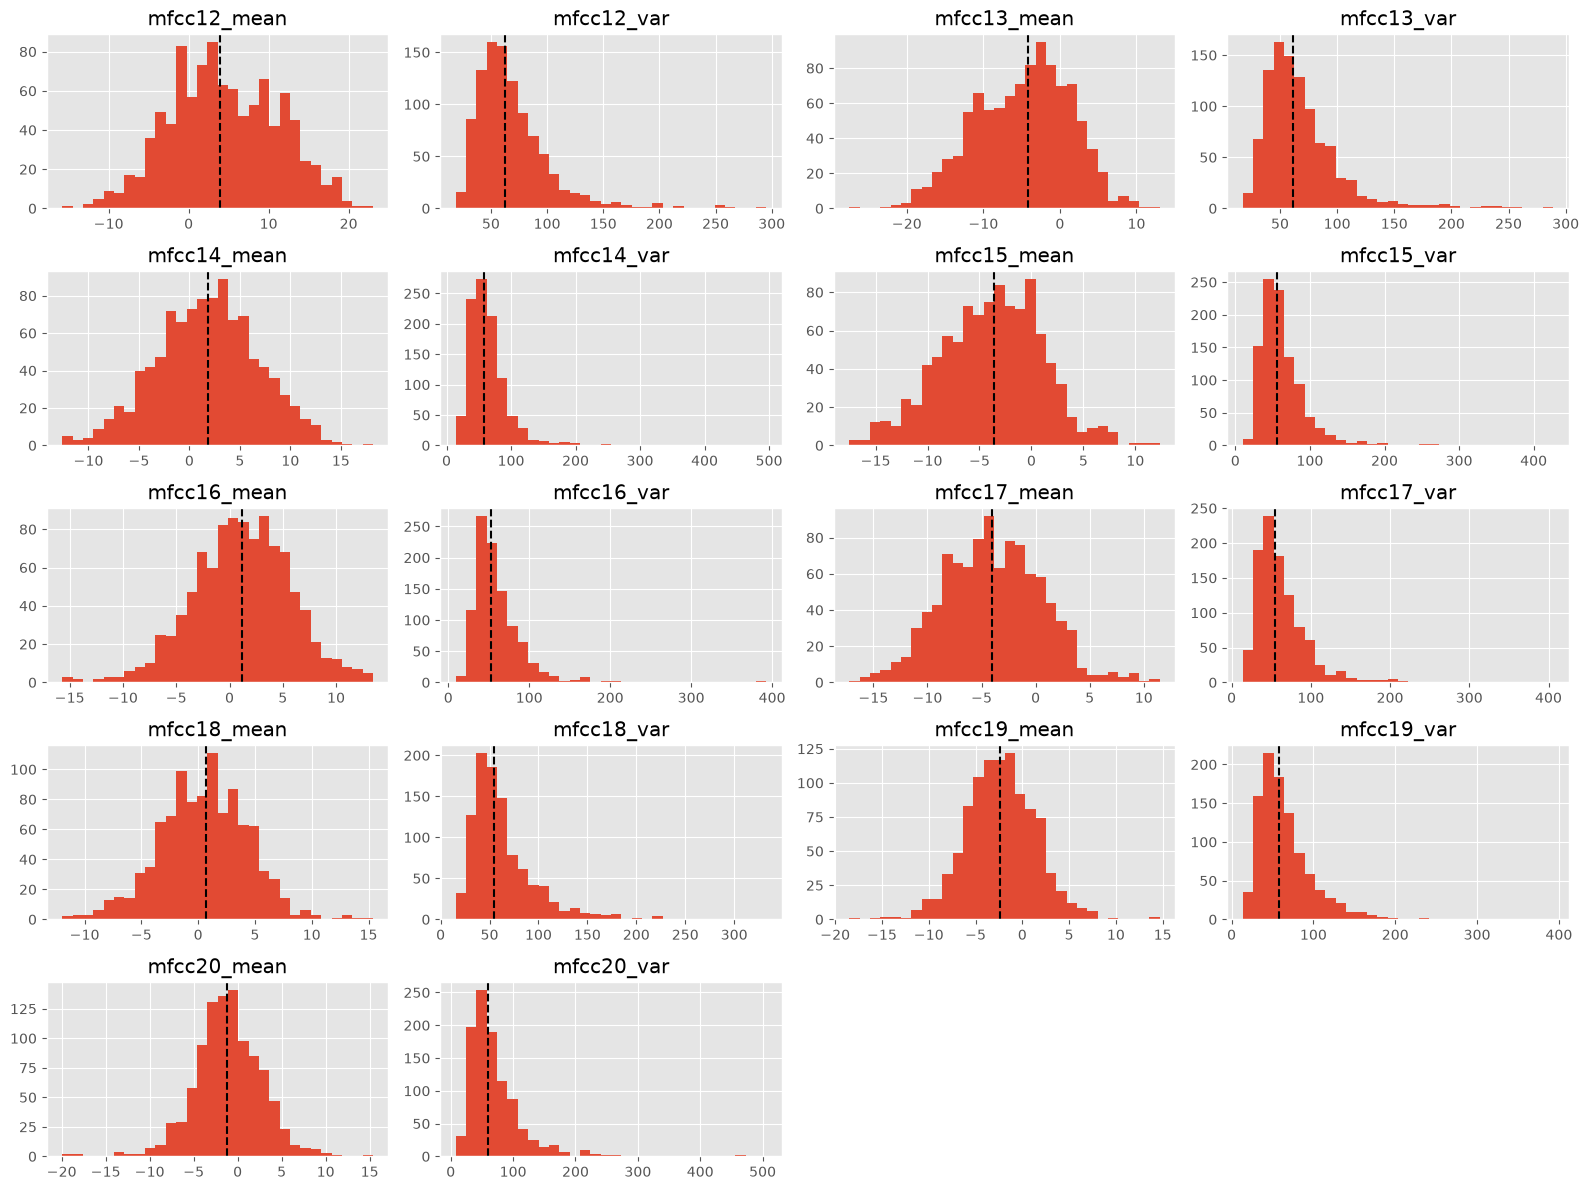

In [17]:
#distributions
with PdfPages("./data/task2_distributions_30.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = f30_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr_30.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

We observe highly unscaled data, some values are centered around 0, while other go up to value of 500. Additionally, we observe again various distributions across the columns.

In [21]:
#variance check
feature_df_descr_30.iloc[2, :].sort_values(ascending=True).head(10)


perceptr_mean              0.001082
harmony_mean               0.001684
zero_crossing_rate_var     0.003024
rms_var                    0.003634
perceptr_var               0.006500
chroma_stft_var            0.007735
harmony_var                0.011653
zero_crossing_rate_mean    0.041821
rms_mean                   0.065683
chroma_stft_mean           0.081705
Name: std, dtype: float64

Even though we have no features with std=0, we have 6 columns with std<0.01, which is very small and we will (todo).

to delete:
- length
- harmony_mean
- perceptr_mean
- perceptr_var
- zero_crossing_rate_var
- zero_crossing_rate_mean?
- rms_var? 

maybe it would be better to keep one of the rms and zero_crossings, todo

In [ ]:
col_to_drop = feature_df_descr_30.iloc[2, :].sort_values(ascending=True).head(10)

In [22]:
#mean check
feature_df_descr_30.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr_30.iloc[1, :].max()
mean_min = feature_df_descr_30.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 1844345.0425923471, the lowest mean value: -144.4729870956242


Madre mia...

In [23]:
#min check
feature_df_descr_30.iloc[3, :].sort_values(ascending=True).head(5)

mfcc1_mean   -552.120056
mfcc3_mean    -89.870193
mfcc5_mean    -38.890347
mfcc7_mean    -32.930431
mfcc9_mean    -31.640574
Name: min, dtype: float64

In [24]:
#max check
feature_df_descr_30.iloc[7, :].sort_values(ascending=False).head(10)

rolloff_var                8.660900e+06
spectral_centroid_var      3.036843e+06
spectral_bandwidth_var     6.947848e+05
length                     6.758080e+05
mfcc1_var                  2.824344e+04
rolloff_mean               8.677673e+03
spectral_centroid_mean     4.435244e+03
mfcc2_var                  4.025973e+03
spectral_bandwidth_mean    3.509646e+03
mfcc3_var                  2.924435e+03
Name: max, dtype: float64

In [15]:
feature_df_descr_3 = f3_df[num_columns].describe()
feature_df_descr_3

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,9990.0,9990.000000,9990.000000,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,...,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000
mean,66149.0,0.379534,0.084876,0.130859,2.676388e-03,2199.219431,4.166727e+05,2241.385959,1.182711e+05,4566.076592,...,1.448240,49.988755,-4.198706,51.962753,0.739943,52.488851,-2.497306,54.973829,-0.917584,57.322614
std,0.0,0.090466,0.009637,0.068545,3.585628e-03,751.860611,4.349644e+05,543.854449,1.013505e+05,1642.065335,...,5.735149,34.442816,5.677379,36.400669,5.181313,38.177120,5.111799,41.585677,5.253243,46.444212
min,66149.0,0.107108,0.015345,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.183520e+03,658.336276,...,-26.850016,1.325786,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,0.282131
25%,66149.0,0.315698,0.079833,0.083782,6.145900e-04,1630.680158,1.231961e+05,1887.455790,4.876553e+04,3378.311110,...,-2.227478,29.584894,-7.951722,29.863448,-2.516638,29.636197,-5.734123,30.496412,-4.004475,30.011365
50%,66149.0,0.384741,0.085108,0.121253,1.491318e-03,2208.628236,2.650692e+05,2230.575595,8.996072e+04,4631.377892,...,1.461623,41.702393,-4.443021,42.393583,0.733772,41.831377,-2.702366,43.435253,-1.030939,44.332155
75%,66149.0,0.442443,0.091092,0.176328,3.130862e-03,2712.581884,5.624152e+05,2588.340505,1.585674e+05,5591.634521,...,5.149752,59.274619,-0.726945,61.676964,3.888734,62.033906,0.514246,65.328602,2.216603,68.210421
max,66149.0,0.749481,0.120964,0.442567,3.261522e-02,5432.534406,4.794119e+06,3708.147554,1.235143e+06,9487.446477,...,39.144405,683.932556,34.048843,529.363342,36.970322,629.729797,31.365425,1143.230591,34.212101,910.473206


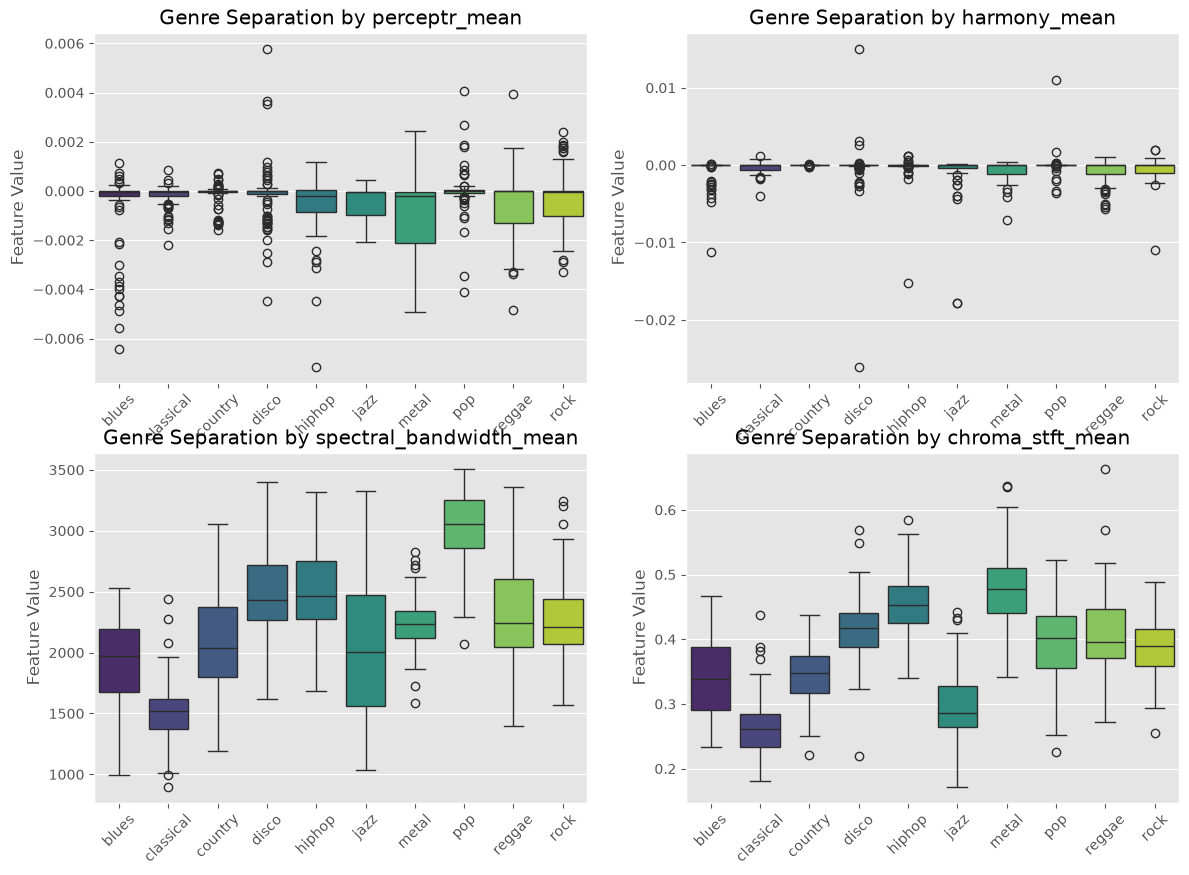

In [51]:
#primary target separation inspection
'''
length
- harmony_mean
- perceptr_mean
- perceptr_var
- zero_crossing_rate_var
- zero_crossing_rate_mean?
- rms_var? 
'''
to_inspect = ["perceptr_mean",
              "harmony_mean",
              "spectral_bandwidth_mean",
              "chroma_stft_mean"
              
              ]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=f30_df, x='label', y=feature, ax=axes[i], hue="label",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()

#### F3_df columns

In [26]:
feature_df_descr_3 = f3_df[num_columns].describe()
feature_df_descr_3

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,9990.0,9990.000000,9990.000000,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9990.000000,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000
mean,66149.0,0.379534,0.084876,0.130859,2.676388e-03,2199.219431,4.166727e+05,2241.385959,1.182711e+05,4566.076592,1.628790e+06,0.102578,0.002620,-0.000365,1.259757e-02,-0.000396,5.601553e-03,124.887709,-145.424643,2808.904199,100.988234,588.795354,-9.995014,374.137619,37.243725,183.911272,-2.009099,143.817714,15.395436,107.784375,-5.823034,98.505164,10.766659,74.795022,-7.569825,74.309310,8.283669,68.803998,-6.504168,63.812684,4.936315,57.790413,-5.186272,57.130389,2.164629,54.069345,-4.175271,52.678281,1.448240,49.988755,-4.198706,51.962753,0.739943,52.488851,-2.497306,54.973829,-0.917584,57.322614
std,0.0,0.090466,0.009637,0.068545,3.585628e-03,751.860611,4.349644e+05,543.854449,1.013505e+05,1642.065335,1.489398e+06,0.045651,0.003614,0.001699,1.263324e-02,0.001108,6.653225e-03,32.911676,106.456350,2596.256821,34.673178,459.705227,23.972522,294.470578,17.804460,133.164251,13.568717,109.272584,12.652512,75.900398,11.088698,65.536682,11.123007,45.881275,9.368422,44.733012,8.841558,41.864203,7.821168,40.218357,7.563187,37.481013,7.132049,35.746539,6.084283,37.715592,5.929457,37.251966,5.735149,34.442816,5.677379,36.400669,5.181313,38.177120,5.111799,41.585677,5.253243,46.444212
min,66149.0,0.107108,0.015345,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.183520e+03,658.336276,1.145102e+03,0.013525,0.000005,-0.026672,9.312309e-23,-0.008794,4.672045e-08,24.377211,-662.171631,25.190538,-12.053392,9.665931,-104.249832,2.055229,-35.138493,3.540373,-47.886780,9.754141,-34.889263,5.267811,-45.187019,7.561506,-40.323467,6.899100,-39.451752,8.252314,-32.833546,7.584913,-40.008194,4.998892,-23.759195,2.345633,-29.350500,7.806118,-23.390091,3.230073,-30.467087,1.481917,-26.850016,1.325786,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,0.282131
25%,66149.0,0.315698,0.079833,0.083782,6.145900e-04,1630.680158,1.231961e+05,1887.455790,4.876553e+04,3378.311110,5.595514e+05,0.067290,0.000628,-0.000127,4.086402e-03,-0.000579,1.106077e-03,103.359375,-201.474651,1143.226685,76.043871,270.420326,-26.884581,174.570415,24.450934,88.392767,-11.881086,67.975819,5.759286,53.944843,-14.464527,51.585960,2.528776,42.255037,-14.569940,42.856218,1.734222,40.205816,-12.203228,37.617884,-0.433691,34.455327,-10.352716,34.844897,-1.860355,32.415298,-8.184258,31.237773,-2.227478,29.584894,-7.951722,29.863448,-2.516638,29.636197,-5.734123,30.496412,-4.004475,30.011365
50%,66149.0,0.384741,0.085108,0.121253,1.491318e-03,2208.628236,2.650692e+05,2230.575595,8.996072e+04,4631.377892,1.160080e+06,0.097868,0.001390,-0.000013,8.429785e-03

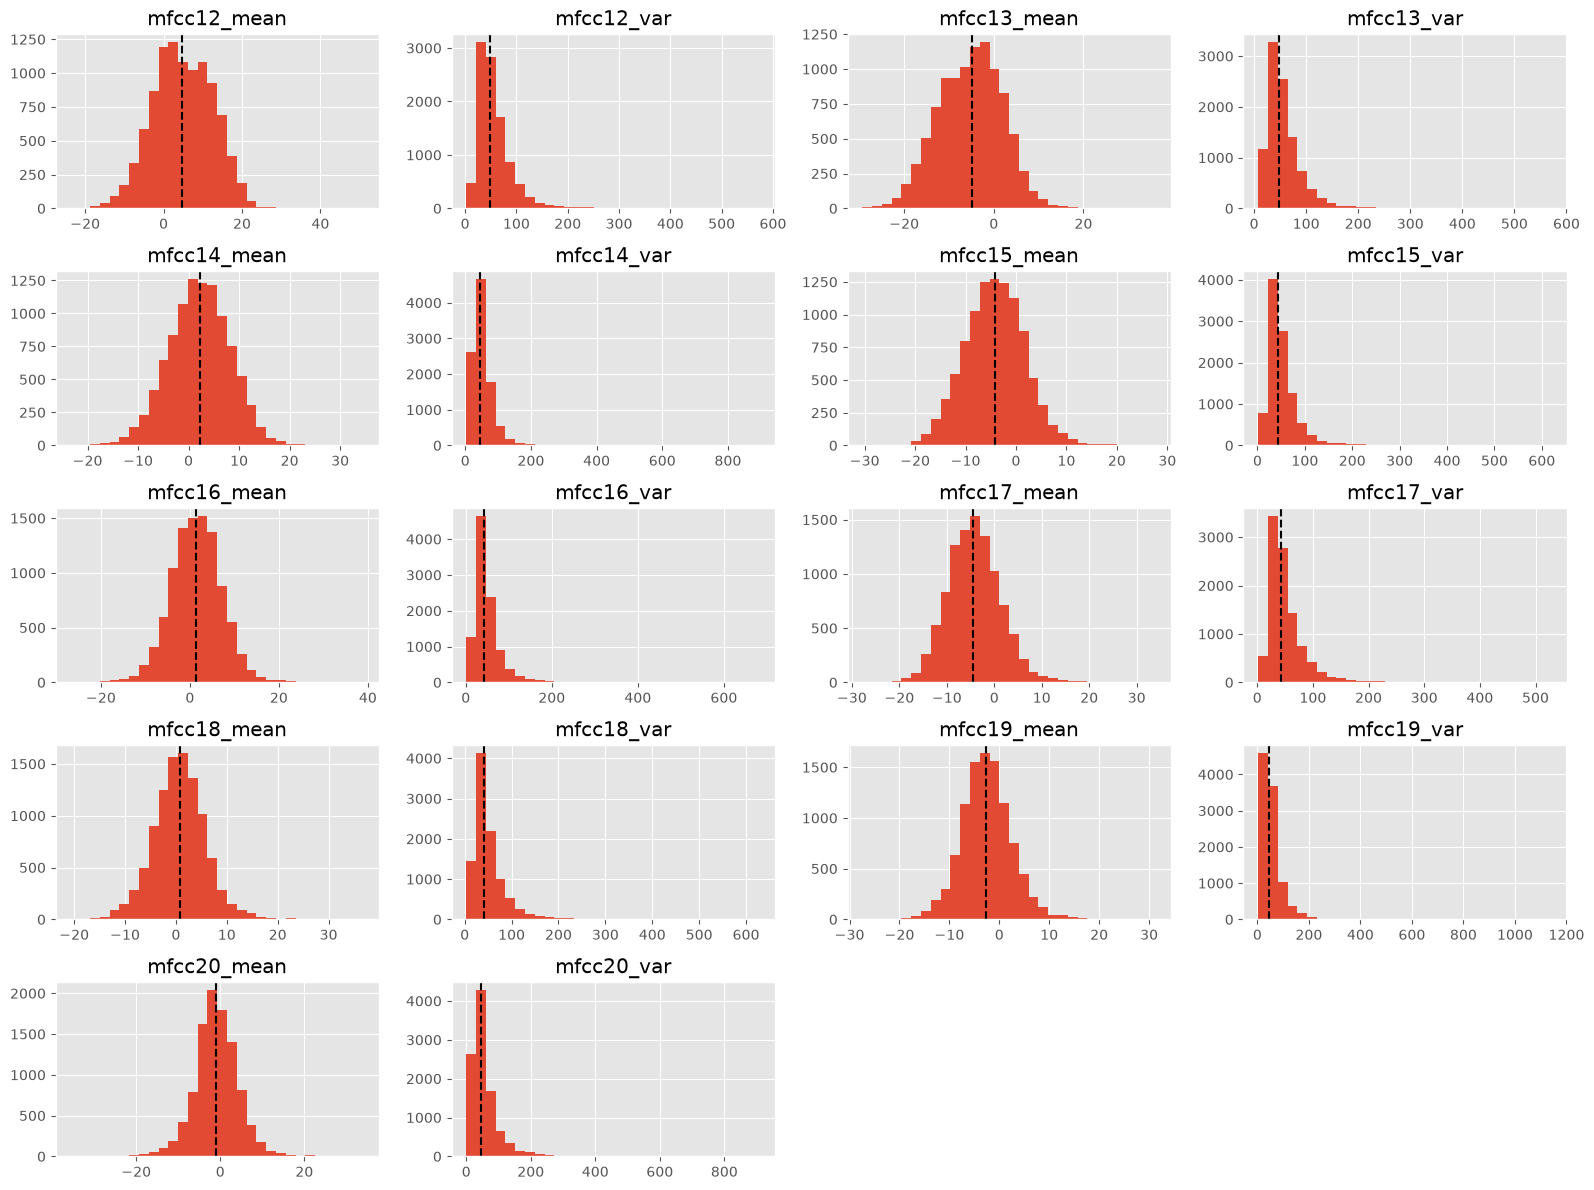

In [27]:
#distributions
with PdfPages("./data/task2_distributions_3.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = f3_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr_3.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

We observe highly unscaled data, some values are centered around 0, while other go up to value of 500. Additionally, we observe again various distributions across the columns.

In [29]:
#variance check
feature_df_descr_3.iloc[2, :].sort_values(ascending=True).head(10)


length                     0.000000
perceptr_mean              0.001108
harmony_mean               0.001699
rms_var                    0.003586
zero_crossing_rate_var     0.003614
perceptr_var               0.006653
chroma_stft_var            0.009637
harmony_var                0.012633
zero_crossing_rate_mean    0.045651
rms_mean                   0.068545
Name: std, dtype: float64

Again, we have no features with std=0 (expect for length), we have 6 columns with std<0.01, which is very small and we will (todo). They actually happen to be the same columns as with f30_df

to delete:
- length
- harmony_mean
- perceptr_mean
- perceptr_var
- zero_crossing_rate_var
- zero_crossing_rate_mean?
- rms_var? 

maybe it would be better to keep one of the rms and zero_crossings, todo

In [31]:
#mean check
feature_df_descr_3.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr_3.iloc[1, :].max()
mean_min = feature_df_descr_3.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 1628789.9708252298, the lowest mean value: -145.42464308544064


Madre mia...

In [32]:
#min check
feature_df_descr_3.iloc[3, :].sort_values(ascending=True).head(5)

mfcc1_mean   -662.171631
mfcc3_mean   -104.249832
mfcc5_mean    -47.886780
mfcc7_mean    -45.187019
mfcc8_mean    -40.323467
Name: min, dtype: float64

In [33]:
#max check
feature_df_descr_3.iloc[7, :].sort_values(ascending=False).head(10)

rolloff_var                1.298320e+07
spectral_centroid_var      4.794119e+06
spectral_bandwidth_var     1.235143e+06
length                     6.614900e+04
mfcc1_var                  4.502738e+04
rolloff_mean               9.487446e+03
spectral_centroid_mean     5.432534e+03
mfcc2_var                  5.131987e+03
mfcc3_var                  4.147786e+03
spectral_bandwidth_mean    3.708148e+03
Name: max, dtype: float64

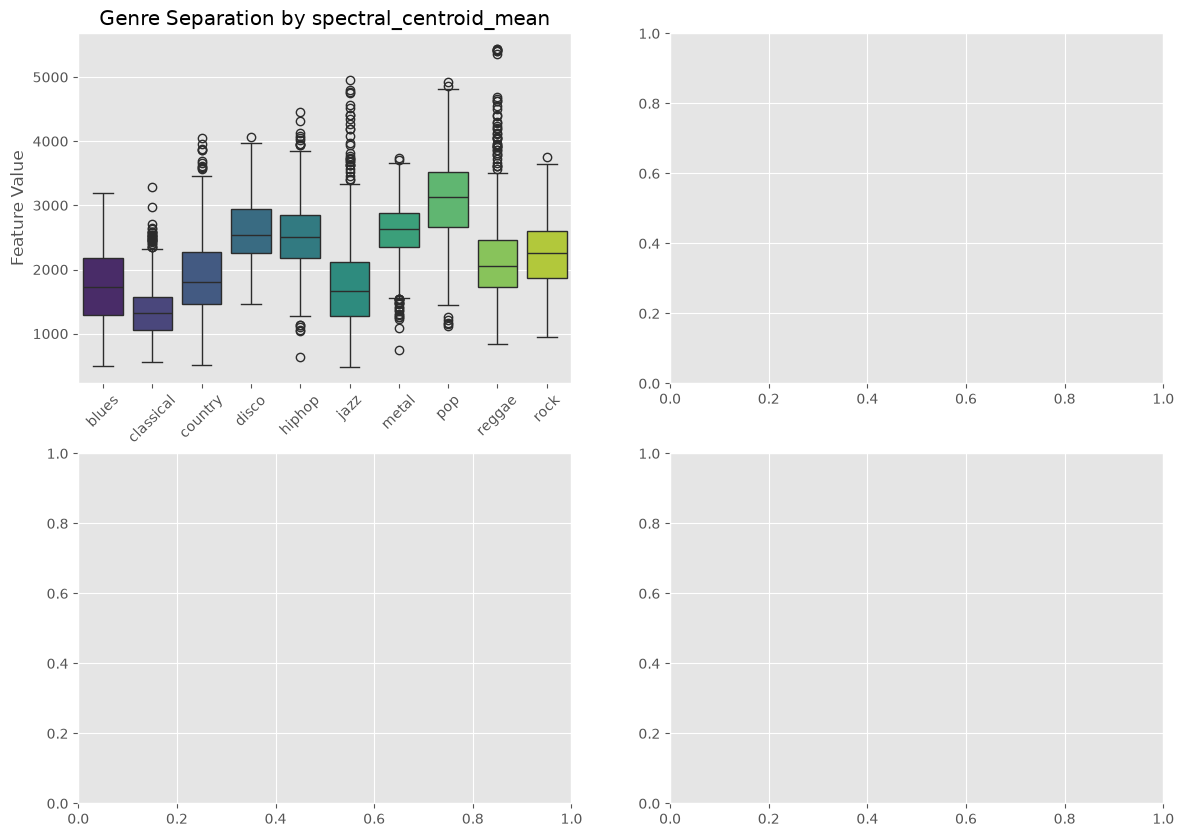

In [40]:
#primary target separation inspection

to_inspect = ["spectral_centroid_mean"
              
              ]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=f3_df, x='label', y=feature, ax=axes[i], hue="label",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()